# Estimating Electricity Outage Duration in Rwanda

## 1. Problem & Data Context

### 1.1 Project Mission
Electricity reliability varies across households depending on infrastructure and location. Estimating how long outages last for grid-connected households can help utility providers and planners anticipate longer interruptions and prioritize maintenance or grid reliability improvements.

This project builds a supervised regression model to estimate electricity outage duration (`outage_duration_minutes`) for grid-connected households in Rwanda. It is intended for electricity providers to use it for estimating the outge duration in minutes which helps them to improve their services and plan better for those households.

### 1.2 Dataset Description
This analysis uses household-level survey data from the 2022 Rwanda Multi-Tier Framework (MTF) Energy Survey (`SECTION_C1.csv`), containing **5,706** household records (`hhid`, one row per household) across **280** columns covering grid status, outage experiences, and household/geographic attributes.

Because the modeling goal is to estimate outage duration on the grid, the scope narrows from all surveyed households (`C002` in `{0, 1}`) to grid-connected households (`C002 == 1`, **2,649** households), and then to records with valid outage duration unit information (`C032B_UNITY` not null among grid-connected households, **1,782** rows).

### 1.3 Prediction Objective & Modeling Scope
- **Task type:** Supervised regression on a continuous numerical target (`outage_duration_minutes`, measured in minutes and capped at 300 minutes).
- **Predictors:** Selected household and geographic variables from `SECTION_C1.csv` (such as `DISTRICT`, `HI04`, `C006`, `C012`, `C013`, `C018`, `C019`, and `C038`), evaluated on a held-out test set (`test_size=0.2`, `random_state=42`) with preprocessing fit strictly on the training split to prevent data leakage.

## 2. Data Loading

### 2.1 Data Loading and Initial Inspection

First start by importing all the libraries you will need.

In [84]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor
from sklearn.base import clone

Load the data and inspect its structure

In [85]:
# load the data
df = pd.read_csv('./data/SECTION_C1.csv', low_memory=False)

In [86]:
print(df.shape)

(5706, 280)


The data has `5706` rows and `280` columns.

Find out what each row represents in the data.

In [87]:
# checking to see what each row represents
print("Total rows:", len(df))
print("Unique household IDs:", df['hhid'].nunique())

print("Are all household IDs unique?", len(df) == df['hhid'].nunique())

Total rows: 5706
Unique household IDs: 5706
Are all household IDs unique? True


In the codebook of the data, column `C002` is a yes/no flag for grid connection. `0`means not connected to the national grid and `1` means connected to the national grid.

In [88]:
# houses connected to the grid
connected_to_grid = df[df['C002'] == 1].copy()
connected_to_grid['C002'].value_counts(dropna=False)

C002
1    2649
Name: count, dtype: int64

There are `2649` households connected to the national grid. These are the household I am going to use.

Some rows, were connected to the national grid but have no units for the duration. That means they are connected to the grid but do not record their outage duration units.
Because of that I will filter out the rows that do not have valid duration units so there would be no way of telling whether the outage duration is in minutes or hours.

In [89]:
outage_rows = df[(df['C002'] == 1) & (df['C032B_UNITY'].notna())]
print(len(outage_rows))

1782


This leaves 1782 rows of households that are connected to the grid and have valid outage duration units.

### 2.2 Special Survey Codes.
This survey dataset has codes that represent responses like "don't know", "none", "missing", and "other" instead of using missing values like `Nan`.
- **`888` ("don't know"):** Treated as missing (`NaN`) rather than a genuine numeric quantity or outage duration.
- **`111` ("none"):** Treated as a "none" indicator rather than a valid outage duration or literal count.
- **`555` ("other"):** Treated as its own category.
- **`999` ("missing"):** This code means the response was missing and not available.

### 2.3 Create the Target Column from C032B and C032B_UNITY
I will use the `C032B` which is the raw duration value and `C032B_UNITY` which is the duration unit to create the target column `outage_duration_minutes`. I will have to convert the rows whose units are in hours to minutes.
First I need to find out how many rows have a particular unit.

In [90]:
# understand which rows have a particular unit (hours or minutes)
df.groupby('C032B_UNITY')['C032B'].describe()

,count,mean,std,min,25%,50%,75%,max
C032B_UNITY,,,,,,,,
1.0,468.0,7.029915,8.293541,5.0,5.0,5.0,5.0,120.0
2.0,1314.0,27.378234,28.516147,5.0,5.0,20.0,30.0,120.0


I can see that 468 rows record the outage duration in hours while 1314 rows record their outage duration in minutes.
The maximum value of rows that record their outage duration is 120 hours, which is over 7200 minutes. 

In [91]:
Hour_rows = df[(df['C002'] == 1) & (df['C032B_UNITY'] == 1)]
print(Hour_rows['C032B'].value_counts(dropna=False))

C032B
5.0      415
10.0      18
25.0      13
15.0       6
20.0       5
40.0       4
30.0       4
60.0       2
120.0      1
Name: count, dtype: int64


After checking the counts of each value in the hours row, 415 rows have a value of 5 hours and the remaining 53 values are above that. That 53 values above 5 hours will dominate the mean when they are converted to minutes. To prevent this from happening, I will cap the minutes at 300, so every row that has a value above 5 hours will be capped.

In [92]:
target_df = outage_rows.copy()
target_df['outage_duration_minutes'] = np.where(
    target_df["C032B_UNITY"] == 1,
    target_df["C032B"] * 60,
    target_df["C032B"]
)

# cap the values at 300 minutes
target_df['outage_duration_minutes'] = (target_df['outage_duration_minutes'].clip(upper=300))

target_col = "outage_duration_minutes"

### 2.4 Scope & Cohort Filtering
After auditing special codes and defining `outage_duration_minutes`, I narrow the dataset to grid-connected households with valid outage duration records and track counts at each step:
- **Full survey dataset:** `5,706` households (`C002` in `{0, 1}`).
- **Grid-connected households:** `2,649` households (`C002 == 1`).
- **No-outage grid households:** `570` households (`C031B == 111`), set aside as outside the conditional duration target.
- **Modeling cohort:** `1,782` grid-connected households with non-null outage duration unit codes (`C032B_UNITY.notna()`).

## 3. Explore the data

### 3.1 Data Visualizations

### Target Distribution: A histogram of outage_duration_minutes

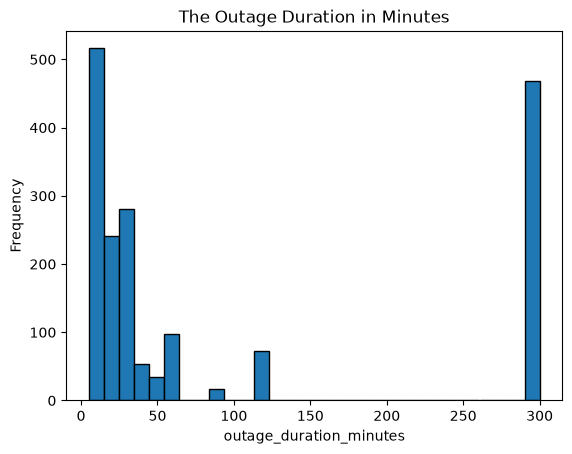

In [93]:
outage = target_df['outage_duration_minutes']
outage.plot.hist(bins=30, edgecolor='black', title='The Outage Duration in Minutes')
plt.xlabel('outage_duration_minutes')
plt.show()

The bulk is at the left side of the histogram. It indicates that most of the households have the smaller values that is why the tallest bar is at the left. At 300, the spike pull the mean above the median. The empty gap between 120 and 290 shows that no values fall here because the raw values of the minutes group range from 5 to 120 so they are not converted and 120 is the largest that group can produce. the hours group also has vlaues from 5 to 120 and the lowest it can produce when multiplied by 60 is 300. this is why there is the empty space. the spike is made of the 415 households that recorded 5 hours and the 53 that recorded more than 5 hours but I capped. I capped the values at 300 minutes so that 53 extreme answers wouldn't dominate the MSE.

### Feature Selection
I chose these feature to investigate based on their relevancee to electricity outages. 

The table below lists all variables from `SECTION_C1.csv` that were excluded from the predictor matrix (`X`) when modeling typical-week electricity outage duration on the national grid, along with the reason for each exclusion.

| Variables | Reason Excluded |
| :--- | :--- |
| `C032B`, `C032B_UNITY`, `C032b_unity` | **Direct Target & Unit Inputs:** These columns directly construct the target variable (`y` typical-week outage duration in minutes) and cannot be used as predictors. |
| `C029B`, `C030B` | **Mathematical Complements (Target Leakage):** Daily/nightly and evening hours of electricity availability in typical months are direct complements of outage duration, leaking the target outcome into `X`. |
| `C027A`–`C027M`, `C028A`, `C029A`, `C030A`, `C031A`, `C032A`, `C032A_UNITY`, `C032a_unity` | **Worst-Month / Worst-Week Metrics:** Measure worst-month or worst-week outages and availability rather than typical-week behavior, blurring the modeling objective and introducing overlap with the target. |
| `C033`, `C034`, `C036`, `C037_FIRST`, `C037_SECOND` | **Post-Outage Reactions & Consequences:** Capture household responses or impacts after outages occur (backup lighting/appliances, voltage-damaged appliances, and most serious grid problems) rather than clean pre-outcome predictors. |
| `C041`, `C042`, `C043`, `C044`, `C045`, `C046`, `C047`, `C048`, `C049`, `C050`, `C051`, `C052`, `C053`, `C054`, `C055`, `C056`, `C057`, `C058`, `C059`, `C060`, `C061`, `C062`, `C063`, `C064`, `C065`, `C066`, `C067`, `C068A`–`C068M`, `C069C`–`C073D`, `C073C_UNITY`, `C073C_unity`, `C073D_UNITY`, `C073D_unity`, `C074`, `C075`, `C076`, `C077`, `C078_FIRST`, `C078_SECOND`, `C079`, `C080`, `C081` | **Mini-Grid Module:** Belong to the mini-grid survey section (connection reasons, tariffs, mini-grid outages, backup sources, and mini-grid issues), which applies to a different supply regime than the national grid. |
| `C082`, `C083`, `C084`, `C085`, `C086A`–`C086M`, `C087`, `C088A`–`C088E`, `C089`, `C090`, `C091`, `C092`, `C093`, `C094`, `C095`, `C096`, `C097`, `C098`, `C099`, `C100`, `C100_UNITY`, `C100_unity`, `C101`, `C102_FIRST`, `C102_SECOND`, `C103`, `C104`, `C105` | **Generator Module (Equipment-Specific / Out of Scope):** Describe generator ownership, fuel usage, maintenance, and generator outages rather than national-grid reliability. |
| `C106`, `C107A`–`C107N`, `C108A`–`C108D`, `C109`, `C110`, `C111`, `C112`, `C113`, `C114`, `C115`, `C116`, `C117`, `C118`, `C119`, `C120`, `C121`, `C122_FIRST`, `C122_SECOND`, `C123`, `C124`, `C125`, `C126` | **Rechargeable Batteries & Inverters Module:** Cover battery/inverter capacity, charging costs, and disposal—storage equipment details unrelated to national-grid outage duration. |
| `C127`, `C152`, `C153`, `C154`, `C155`, `C156`, `C157`, `C158`, `C159`, `C160`, `C161`, `C162`, `C163`, `C164_1`–`C164_8`, `C165`, `C166`, `C167`, `C168`, `C169`, `C170_1`–`C170_8` | **Solar Devices Module:** Capture standalone solar device payments, usage shifts, and desired appliances rather than national-grid infrastructure or fault duration. |
| `C172`, `C173`, `C174`, `C175`, `C176`, `C177` | **Mobile Phones & Internet Access:** Track phone ownership, external phone charging, and internet access, which add noise without directly explaining grid outage duration. |
| `PROVINCE` | **Redundant Geography:** Fully nested within `DISTRICT`; keeping both introduces redundant encoding and collinearity. |
| `Cluster`, `PSU`, `HI05`, `HH_Quest_Number`, `C001`, `hhid`, `camp`, `ref_weight`, all `*_OTHER` / `*_Other` fields | **Identifiers, Survey Metadata & Free-Text Fields:** Administrative/sampling IDs and unstandardized open-ended text fields do not generalize as predictive features. |
| `HH_WT` | **Survey Sampling Weight:** Represents household sampling weight for population-level estimation; should only be passed as `sample_weight` if weighted modeling is used, never as a column in `X`. |

In [94]:
candidate_cols = [
    "C031B", "C006", "DISTRICT", "HI04", "TYPEHH",
    "C008", "C012", "C013", "C014", "C015", "C016",
    "C018", "C019", "C026", "C028B", "C035", "C038", "C171"
]

candidate_df = outage_rows[candidate_cols].copy()

print("Number of observations:", len(candidate_df))
print("Number of candidate features:", len(candidate_cols))

Number of observations: 1782
Number of candidate features: 18


Some of these columns could have the special codes we talked about earlier. Seeing the number of codes I have to deal with will help me decide whether I want to keep that particular column as a feature or not.

In [95]:
special_codes = [111, 888, 555, 999]

special_code_summary = pd.DataFrame({
    code: (candidate_df == code).sum()
    for code in special_codes
})

special_code_summary["total_special_codes"] = special_code_summary.sum(axis=1)

print(special_code_summary)

          111  888  555   999  total_special_codes
C031B       0    0    0     0                    0
C006        0    0    0     0                    0
DISTRICT    0    0    0     0                    0
HI04        0    0    0     0                    0
TYPEHH      0    0    0     0                    0
C008        0    0    0     0                    0
C012       29    0   24     0                   53
C013        0    0   83     0                   83
C014        0    0    0     0                    0
C015        0    0    0     0                    0
C016        0    0    0     0                    0
C018       30    0   52     0                   82
C019        0    0   53     0                   53
C026        0    0    0     0                    0
C028B       0    0    0     0                    0
C035      201    0    0  1059                 1260
C038        0    2    0     0                    2
C171        0    0    0     0                    0


Dropped:
- C035: 1260 of 1782 rows are special codes so it is mostly unusable.
- C013: 
- C014:
- C015:
- C016:
- C171:


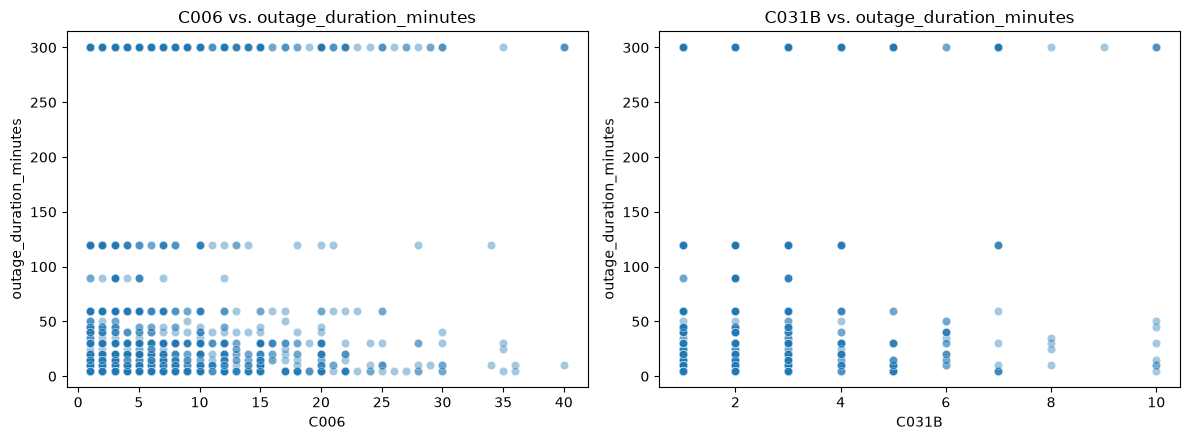

In [96]:
numeric_cols = ["C006", "C031B"]

fig, axes = plt.subplots(1, len(numeric_cols), figsize=(12, 4.5))

for ax, col in zip(axes, numeric_cols):
    plot_df = target_df[[col, target_col]].dropna()
    sns.scatterplot(
        data=plot_df,
        x=col,
        y=target_col,
        alpha=0.4,
        ax=ax,
    )
    ax.set_title(f"{col} vs. {target_col}")
    ax.set_xlabel(col)
    ax.set_ylabel(target_col)

plt.tight_layout()
plt.show()

The scatter plots show that both the numeric columns are do not show a visible trend. The points stack at discrete values so neither feature is strong linearly.

In [97]:
# 1. Define features and target
target = "outage_duration_minutes"
numeric_features = ["C031B", "C006"]
categorical_features = [
    "DISTRICT",
    "HI04",
    "TYPEHH",
    "C008",
    "C012",
    "C018",
    "C019",
    "C026",
    "C028B",
    "C038",
]
selected_features = numeric_features + categorical_features

Cells `C006` and `C031B` are numeric columns because they record the number of years a household has been connected to the grid and the number of outages that happen in a week.

## 4. Data Preparation
I am using an 80/20 split for the data so 80% will be used to train and 20% of the data will be used to test. I replaced the `888` values in the `C038` columns since it is the only column in our target that has the value `888`.

In [98]:
X = target_df[selected_features].copy()
y = target_df[target_col]

X["C038"] = X["C038"].replace(888, np.nan)   # 888 = "don't know" -> missing

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(X_train.shape, X_test.shape)

(1425, 12) (357, 12)


In [99]:
preprocess = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric_features), # fill missing values with the median.
    ("cat", Pipeline([
        ("imp", SimpleImputer(strategy="most_frequent")), # fill missing values with the most frequent one
        ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]), categorical_features),
])

X_train_enc = preprocess.fit_transform(X_train)   # fit on train only
X_test_enc = preprocess.transform(X_test)

scaler = StandardScaler().fit(X_train_enc)        # fit on train only
X_train_s = scaler.transform(X_train_enc)
X_test_s = scaler.transform(X_test_enc)

feature_names = preprocess.get_feature_names_out()
print(X_train_s.shape, X_test_s.shape)

(1425, 67) (357, 67)


cat__DISTRICT_37.0    0.115117
cat__C028B_1.0        0.106953
cat__C028B_0.0       -0.106953
cat__C019_2.0         0.101883
cat__HI04_1.0        -0.086215
cat__HI04_2.0         0.086215
cat__DISTRICT_36.0    0.083545
cat__DISTRICT_41.0    0.082742
cat__DISTRICT_22.0    0.082507
cat__DISTRICT_53.0   -0.076394
Name: target, dtype: float64
Most correlated feature: cat__DISTRICT_37.0


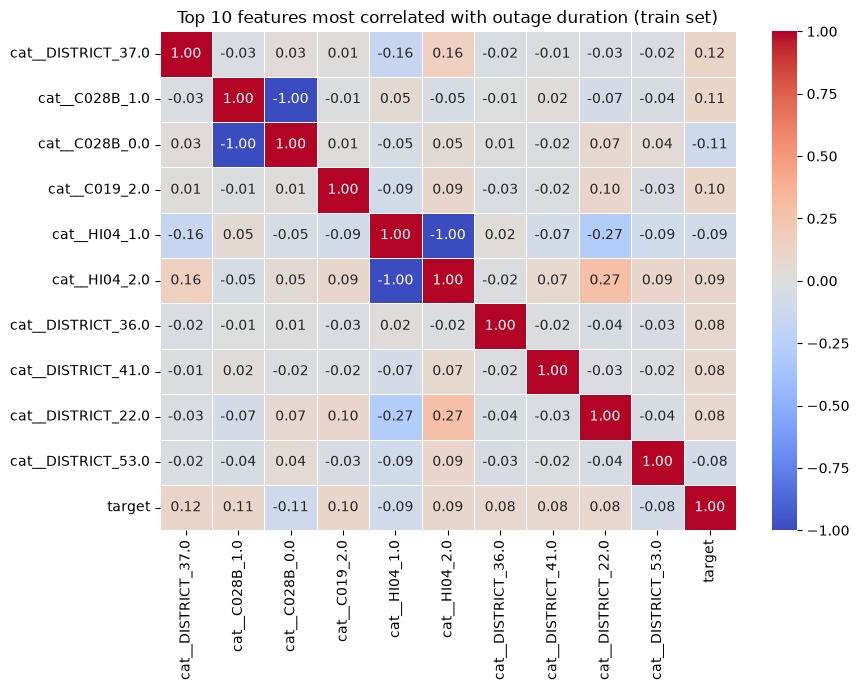

In [100]:
train_df = pd.DataFrame(X_train_s, columns=feature_names)
train_df["target"] = y_train.values

corr = train_df.corr()["target"].drop("target")
top_corr = corr.reindex(corr.abs().sort_values(ascending=False).index)
print(top_corr.head(10))

best_feat = top_corr.index[0]   # reused later for the before/after scatter plots
print("Most correlated feature:", best_feat)

top_cols = list(top_corr.head(10).index) + ["target"]
plt.figure(figsize=(9, 7))
sns.heatmap(train_df[top_cols].corr(), annot=True, fmt=".2f",
            cmap="coolwarm", vmin=-1, vmax=1, center=0, linewidths=0.5)
plt.title("Top 10 features most correlated with outage duration (train set)")
plt.tight_layout()
plt.show()

The heatmap shows the 10 features most correlated with outage duration on the training set. Every correlation is weak (the strongest is about 0.12, for district 37), so no single feature explains duration linearly. Because of this I kept the full set of 12 features instead of trimming to the top few, and I expect the linear models to do only modestly better than predicting the mean.

DISTRICT    0.318088
C006        0.187556
C018        0.115309
C012        0.074957
C031B       0.071704
C019        0.067219
C026        0.042320
HI04        0.040183
C038        0.026628
C028B       0.023898
C008        0.018272
TYPEHH      0.013867
dtype: float64


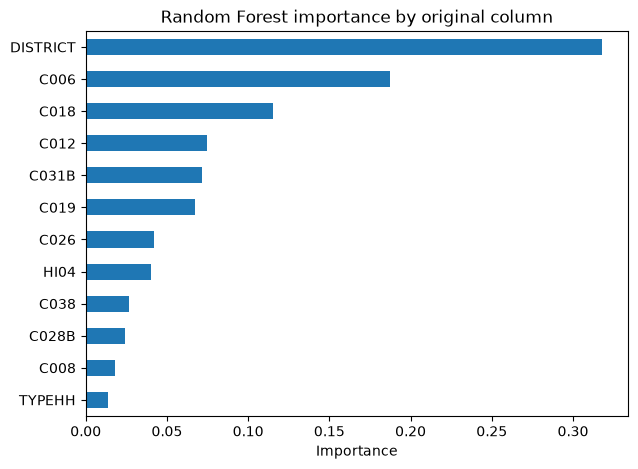

In [101]:
rf_imp = RandomForestRegressor(n_estimators=200, random_state=42).fit(X_train_s, y_train)
imp = pd.Series(rf_imp.feature_importances_, index=feature_names)

def original_col(name):
    name = name.split("__", 1)[1]
    return next((c for c in categorical_features if name.startswith(c + "_")), name)

imp_by_col = imp.groupby(imp.index.map(original_col)).sum().sort_values(ascending=False)
print(imp_by_col)

imp_by_col[::-1].plot.barh(figsize=(7, 5), title="Random Forest importance by original column")
plt.xlabel("Importance")
plt.show()

Random Forest importance, summed back to the original columns, ranks DISTRICT first (0.32), then C006 (0.19) and C018 (0.12). C006 has almost no linear correlation with the target (-0.04) but ranks second in importance, which suggests a non-linear relationship that tree models can capture and linear regression cannot. DISTRICT’s score is likely inflated because it has many categories, so I treat this ranking as a guide, not proof.

## 5. Model training and comparison
### 5.1 Helper function
One function fits any model and returns its train and test MSE, so all four models are evaluated the same way on the same test set.

In [102]:
def run_model(model):
    """Fit one model on the training data and return (train MSE, test MSE)."""
    model.fit(X_train_s, y_train)
    train_mse = mean_squared_error(y_train, model.predict(X_train_s))
    test_mse = mean_squared_error(y_test, model.predict(X_test_s))
    return train_mse, test_mse

### 5.2 Baseline: all four models with default settings

In [103]:
baseline_models = {
    "SGD": SGDRegressor(random_state=42),
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(random_state=42),
}

before = {name: run_model(m) for name, m in baseline_models.items()}
print(pd.DataFrame(before, index=["Train MSE", "Test MSE"]).T.round(1))

                   Train MSE  Test MSE
SGD                  13149.8   15083.3
Linear Regression    13121.7   15054.7
Decision Tree          368.0   21924.9
Random Forest         2262.4   13521.8


### 5.3 Tune SGDRegressor
I try different learning rates (eta0), regularization strengths (alpha) and numbers of epochs. Each setting is scored on a validation split taken from the training data, so the test set is never used for tuning.

In [104]:
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_s, y_train, test_size=0.2, random_state=42
)

results = []
for eta0 in [1e-5, 1e-4, 1e-3]:            # learning rate
    for alpha in [0.01, 0.1, 1, 10]:        # regularization strength
        for epochs in [50, 200, 500]:       # number of epochs
            sgd = SGDRegressor(learning_rate="constant", eta0=eta0, alpha=alpha,
                               max_iter=epochs, tol=None, random_state=42)
            sgd.fit(X_tr, y_tr)
            results.append({
                "eta0": eta0, "alpha": alpha, "epochs": epochs,
                "train_mse": mean_squared_error(y_tr, sgd.predict(X_tr)),
                "val_mse": mean_squared_error(y_val, sgd.predict(X_val)),
            })

tuning_df = pd.DataFrame(results).sort_values("val_mse")
print(tuning_df.head(10).to_string(
    formatters={"eta0": "{:.0e}".format, "train_mse": "{:.1f}".format, "val_mse": "{:.1f}".format}))

print("Validation baseline (predict train mean):",
      round(mean_squared_error(y_val, np.full(len(y_val), y_tr.mean())), 1))

best = tuning_df.iloc[0]
best_params = {"eta0": best["eta0"], "alpha": best["alpha"], "max_iter": int(best["epochs"])}
print("Best:", best_params)

    eta0  alpha  epochs train_mse val_mse
7  1e-05    1.0     200   13718.1 13120.4
8  1e-05    1.0     500   13604.9 13246.9
18 1e-04    1.0      50   13602.7 13248.1
19 1e-04    1.0     200   13603.6 13255.3
20 1e-04    1.0     500   13603.3 13256.0
10 1e-05   10.0     200   15090.4 13312.6
31 1e-03    1.0     200   13672.8 13361.7
32 1e-03    1.0     500   13687.7 13375.3
11 1e-05   10.0     500   14983.1 13472.4
22 1e-04   10.0     200   14986.5 13478.3
Validation baseline (predict train mean): 13678.2
Best: {'eta0': np.float64(1e-05), 'alpha': np.float64(1.0), 'max_iter': 200}


### 5.4 Tune Decision Tree and Random Forest
GridSearchCV with 5-fold cross-validation on the training set only. Linear regression has no hyperparameters to tune, so it is unchanged.

In [105]:
tuned_models = {
    "SGD": SGDRegressor(learning_rate="constant", eta0=best_params["eta0"],
                        alpha=best_params["alpha"], max_iter=best_params["max_iter"],
                        tol=None, random_state=42),
    "Linear Regression": LinearRegression(),
}

searches = {
    "Decision Tree": (DecisionTreeRegressor(random_state=42),
                    {"max_depth": [3, 5, 10, None], "min_samples_leaf": [1, 10, 30, 50]}),
    "Random Forest": (RandomForestRegressor(random_state=42),
                    {"n_estimators": [100, 300], "max_depth": [5, 10, None],
                    "min_samples_leaf": [1, 5, 20]}),
}

for name, (model, grid) in searches.items():
    gs = GridSearchCV(model, grid, cv=5, scoring="neg_mean_squared_error", n_jobs=-1)
    gs.fit(X_train_s, y_train)
    print(name, "best:", gs.best_params_, "| CV MSE:", round(-gs.best_score_, 1))
    tuned_models[name] = gs.best_estimator_

Decision Tree best: {'max_depth': 5, 'min_samples_leaf': 50} | CV MSE: 14622.0
Random Forest best: {'max_depth': 10, 'min_samples_leaf': 1, 'n_estimators': 300} | CV MSE: 13469.8


### 5.5 Before vs after tuning

In [106]:
after = {name: run_model(m) for name, m in tuned_models.items()}

comparison = pd.DataFrame({
    "Train MSE (before)": {n: v[0] for n, v in before.items()},
    "Test MSE (before)":  {n: v[1] for n, v in before.items()},
    "Train MSE (after)":  {n: v[0] for n, v in after.items()},
    "Test MSE (after)":   {n: v[1] for n, v in after.items()},
})

mean_pred = y_train.mean()
comparison.loc["Baseline (predict train mean)"] = [
    mean_squared_error(y_train, np.full(len(y_train), mean_pred)),
    mean_squared_error(y_test, np.full(len(y_test), mean_pred)),
] * 2

print(comparison.round(1))

                               Train MSE (before)  Test MSE (before)  \
SGD                                       13149.8            15083.3   
Linear Regression                         13121.7            15054.7   
Decision Tree                               368.0            21924.9   
Random Forest                              2262.4            13521.8   
Baseline (predict train mean)             15113.6            14510.1   

                               Train MSE (after)  Test MSE (after)  
SGD                                      13612.2           14217.0  
Linear Regression                        13121.7           15054.7  
Decision Tree                            14013.4           14194.3  
Random Forest                             8618.4           13014.3  
Baseline (predict train mean)            15113.6           14510.1  


The best model is Random Forest, with the lowest test MSE after tuning (13014.3). Tuning helped the models that overfit most. The best settings were chosen on the training set only: SGD used a learning rate of 1e-5, alpha = 1 and 200 epochs (validation split); the Decision Tree used max_depth = 5 and min_samples_leaf = 50; the Random Forest used max_depth = 10, min_samples_leaf = 1 and 300 trees (both by 5-fold cross-validation). The Decision Tree improved the most: test MSE fell from 21,925 to 14,194 (about 35% lower), and the train-test gap shrank from about 21,557 to about 181, because limiting its depth and leaf size stopped it from memorizing the training data. Random Forest improved from 13,522 to 13,014, and SGD from 15,083 to 14,217. Linear Regression has no hyperparameters, so its results are unchanged. After tuning, Random Forest is the only model that clearly beats the predict-the-mean baseline (14,510), at about 10% lowerly beats the predict-the-mean baseline (14,510), at about 10% lower.

## 6. Required Plots
### 6.1 Loss Curve

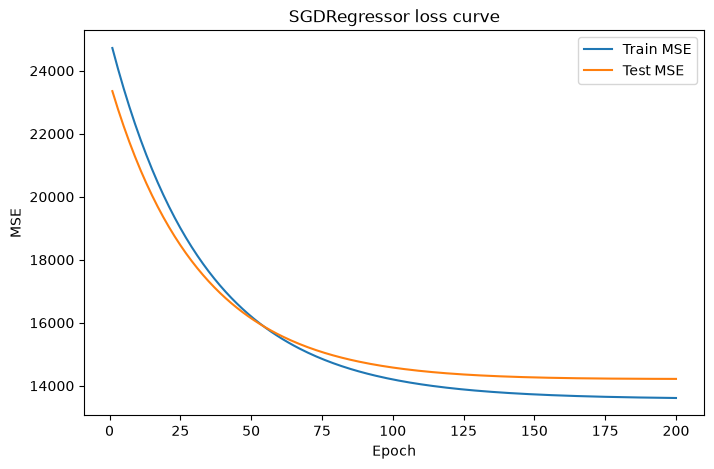

Final epoch -> train: 13612.5 test: 14218.7


In [107]:
sgd = SGDRegressor(
    learning_rate="constant",
    eta0=best_params["eta0"],
    alpha=best_params["alpha"],
    random_state=42,
)

train_curve, test_curve = [], []
for epoch in range(best_params["max_iter"]):
    sgd.partial_fit(X_train_s, y_train)      # one epoch per call
    train_curve.append(mean_squared_error(y_train, sgd.predict(X_train_s)))
    test_curve.append(mean_squared_error(y_test, sgd.predict(X_test_s)))

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(train_curve) + 1), train_curve, label="Train MSE")
plt.plot(range(1, len(test_curve) + 1), test_curve, label="Test MSE")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("SGDRegressor loss curve")
plt.legend()
plt.show()

print("Final epoch -> train:", round(train_curve[-1], 1), "test:", round(test_curve[-1], 1))

The loss curve shows train and test MSE for SGDRegressor over 200 epochs, using the tuned settings (learning rate 1e-5, alpha = 1). Both curves fall quickly at first and then level off, so training has converged and more epochs would not help. At the final epoch, train MSE is 13,612 and test MSE is 14,219, a small gap of about 600 that shows little overfitting. Test MSE is only about 2% below the predict-the-mean baseline (14,510), which confirms the features carry limited linear signal.

### 6.2 Scatter Plot, before

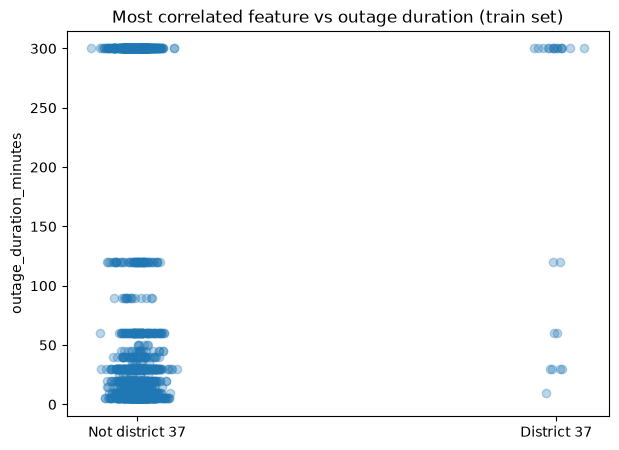

District 37 households in train: 24 of 1425


In [108]:
idx = list(feature_names).index(best_feat)
x_tr = X_train_enc[:, idx].reshape(-1, 1)          # raw 0/1 values, train set

rng = np.random.default_rng(42)
x_jit = x_tr.ravel() + rng.normal(0, 0.03, len(x_tr))   # jitter for display only

plt.figure(figsize=(7, 5))
plt.scatter(x_jit, y_train, alpha=0.3)
plt.xticks([0, 1], ["Not district 37", "District 37"])
plt.ylabel("outage_duration_minutes")
plt.title("Most correlated feature vs outage duration (train set)")
plt.show()
print("District 37 households in train:", int(x_tr.sum()), "of", len(x_tr))

This scatter plots the feature most correlated with outage duration, a district 37 indicator, against the target. Outages in district 37 cluster at the top of the range (many at the 300-minute cap), while the other districts spread from 5 to 300 minutes with most under 60. I kept the feature because it is the strongest single signal I found, but only 24 of the 1,425 training households (about 1.7%) are in district 37, so I treat it as weak evidence.

### 6.3 Scatter Plot, after

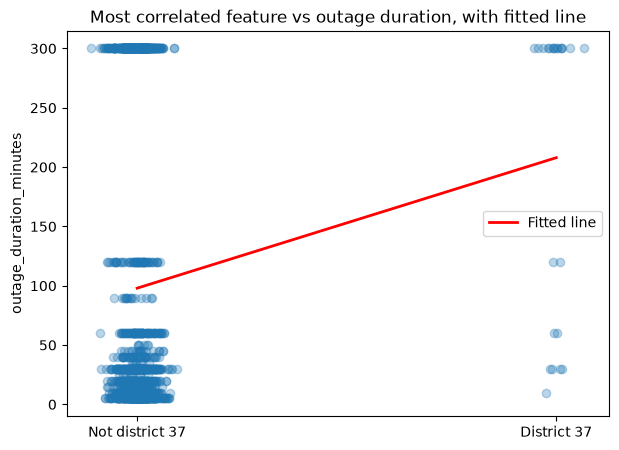

Intercept: 97.9 | Slope: 110.0


In [109]:
lr_one = LinearRegression().fit(x_tr, y_train)      # one-feature model, for this plot only

xs = np.array([[0], [1]])
plt.figure(figsize=(7, 5))
plt.scatter(x_jit, y_train, alpha=0.3)
plt.plot(xs, lr_one.predict(xs), color="red", linewidth=2, label="Fitted line")
plt.xticks([0, 1], ["Not district 37", "District 37"])
plt.ylabel("outage_duration_minutes")
plt.title("Most correlated feature vs outage duration, with fitted line")
plt.legend()
plt.show()

print("Intercept:", round(lr_one.intercept_, 1), "| Slope:", round(lr_one.coef_[0], 1))

The fitted line from a one-feature linear regression predicts about 98 minutes for households outside district 37 and about 208 for district 37, a difference of 110 minutes. The line only joins two group averages, and it misses the large spread of values around each, since the points range from 5 to 300 minutes in both groups. With only 24 district 37 households, that gap is also uncertain. This shows that even the best single feature explains very little of the variation, which matches the near-baseline MSE of the full models.

## 7. Saving the models
All four tuned models are saved, plus the preprocessor and scaler that any app needs to transform new data in the same way (preprocess, then scale, then predict).

In [110]:
os.makedirs("saved_models", exist_ok=True)

for name, model in tuned_models.items():
    joblib.dump(model, f"saved_models/{name.lower().replace(' ', '_')}.joblib")

joblib.dump(preprocess, "saved_models/preprocess.joblib")
joblib.dump(scaler, "saved_models/scaler.joblib")
comparison.round(1).to_csv("saved_models/results_before_after.csv")

best_name = comparison.drop("Baseline (predict train mean)")["Test MSE (after)"].idxmin()
joblib.dump(tuned_models[best_name], "saved_models/best_model.joblib")
print("Best model:", best_name)

Best model: Random Forest


In [111]:
best_name = comparison.drop("Baseline (predict train mean)")["Test MSE (after)"].idxmin()
print("Best model:", best_name)

best_pipeline = Pipeline([
    ("preprocess", clone(preprocess)),     # impute + one-hot encode
    ("scaler", StandardScaler()),          # standardize
    ("model", clone(tuned_models[best_name])),
])

best_pipeline.fit(X_train, y_train)        # X_train = raw columns, before encoding

pipe_test_mse = mean_squared_error(y_test, best_pipeline.predict(X_test))
print("Pipeline test MSE:", round(pipe_test_mse, 1))   # should match the table (13,014.3)

joblib.dump(best_pipeline, "saved_models/best_pipeline.joblib")

Best model: Random Forest
Pipeline test MSE: 13014.3


['saved_models/best_pipeline.joblib']

In [112]:
def predict_one_row(row_index, model_path="saved_models/best_pipeline.joblib"):
    """Load the saved pipeline and predict outage duration for one test-set row."""
    model = joblib.load(model_path)
    row = X_test.iloc[[row_index]]         # a 1-row DataFrame with the raw columns
    return model.predict(row)[0]

pred = predict_one_row(0)
print("Predicted:", round(pred, 1), "| Actual:", y_test.iloc[0])

Predicted: 63.9 | Actual: 25.0


## 8. Conculsion

Random Forest achieved the lowest test MSE after tuning (13,014), about 10% below the predict-the-mean baseline (14,510). The tuned Decision Tree (14,194) and tuned SGD (14,217) each beat the baseline by only about 2%, which is within the noise of a 357-row test set, so I treat them as roughly tied. Closed-form linear regression (15,055) was about 4% worse than the baseline: it fits the training data well (13,122) but generalizes worse than SGD (train-test gap 1,933 vs 605), likely because SGD’s penalty (alpha = 1) shrinks the weights while closed form has no regularization on 67 one-hot columns. Tuning mattered most for the Decision Tree, whose test MSE dropped from 21,925 to 14,194 once its depth and leaf size were limited. Random Forest still overfits somewhat (train 8,618 vs test 13,014), but it is the only model that clearly beats the baseline, which fits the earlier finding that features such as C006 relate to outage duration non-linearly. Overall, the survey variables carry limited information about outage duration, so even the best model explains only about a tenth of the variation in test outage durations.